<a href="https://colab.research.google.com/github/yang200212/MSSP-6070/blob/main/Modules/Week_10/Week10_Participation_Activity_Week_8_Internet_Sales_Improved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8 Participation Activity — Improved Internet Sales Analysis

**Assignment questions**
1. Create an Internet Sales forecast for the next five years.
2. Using summary statistics, identify which product generated the most sales.
3. Plot a trend line on sales.

**Approach:** Check date coverage, use the three complete calendar years (2011–2013), fit a simple linear trend, forecast 2014–2018, summarize product sales, and visualize historical versus predicted values.

> This is a **descriptive classroom forecast**, not a validated business forecast. Three annual observations are too few to establish reliable five-year predictive accuracy.

## 1. Import libraries and locate the dataset

The code looks for the CSV in the current folder or an existing `MSSP-6070` repository. In a fresh Google Colab session, it clones the public repository **only if needed**. You do not need to change the working directory manually.

In [1]:
from pathlib import Path
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

REPO_OWNER = "yang200212"
REPO_NAME = "MSSP-6070"
REPO_URL = f"https://github.com/{REPO_OWNER}/{REPO_NAME}.git"
RELATIVE_CSV = Path("Modules") / "Week_8" / "InternetSales.csv"

# Search common local and Colab locations before attempting to clone.
search_paths = [
    Path.cwd() / "InternetSales.csv",
    Path.cwd() / RELATIVE_CSV,
    Path.cwd() / REPO_NAME / RELATIVE_CSV,
    Path("/content") / "InternetSales.csv",
    Path("/content") / REPO_NAME / RELATIVE_CSV,
]
DATA_PATH = next((path for path in search_paths if path.is_file()), None)

if DATA_PATH is None:
    base_dir = Path("/content") if Path("/content").is_dir() else Path.cwd()
    repo_path = base_dir / REPO_NAME
    if not repo_path.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(repo_path)], check=True)
    DATA_PATH = repo_path / RELATIVE_CSV

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Could not find {RELATIVE_CSV}. Check the repository path or upload "
        "InternetSales.csv into your notebook's working directory. "
        f"Last path checked: {DATA_PATH}"
    )

print(f"Using data file: {DATA_PATH.resolve()}")

Using data file: /content/MSSP-6070/Modules/Week_8/InternetSales.csv


## 2. Load and clean the data

Only three columns are needed for this assignment. Reading these instead of all 60 columns also avoids the mixed-type warning caused by an unrelated column in the original file. Parse dates explicitly, convert `SalesAmount` to numeric, and report missing values before removing unusable rows.

In [2]:
columns = ["OrderDate", "SalesAmount", "EnglishProductName"]
sales_raw = pd.read_csv(
    DATA_PATH,
    usecols=columns,
    encoding="cp1252",  # Preserve the encoding used in the original notebook
    low_memory=False
)

sales = sales_raw.copy()
sales["OrderDate"] = pd.to_datetime(
    sales["OrderDate"], format="%m/%d/%Y", errors="coerce"
)
sales["SalesAmount"] = pd.to_numeric(sales["SalesAmount"], errors="coerce")

print(f"Rows before cleaning: {len(sales_raw):,}")
print("Missing or invalid values by column:")
display(sales[columns].isna().sum().rename("Count").to_frame())

sales = sales.dropna(subset=columns).copy()
sales["Year"] = sales["OrderDate"].dt.year
sales["Month"] = sales["OrderDate"].dt.month

print(f"Rows after cleaning: {len(sales):,}")
print(f"Observed date range: {sales['OrderDate'].min():%Y-%m-%d} to {sales['OrderDate'].max():%Y-%m-%d}")
display(sales.head())

Rows before cleaning: 60,398
Missing or invalid values by column:


,Count
OrderDate,0
SalesAmount,0
EnglishProductName,0


Rows after cleaning: 60,398
Observed date range: 2010-12-29 to 2014-01-28


,EnglishProductName,SalesAmount,OrderDate,Year,Month
0,"Mountain-100 Silver, 38",3399.99,2011-01-19,2011,1
1,"Mountain-200 Silver, 38",2319.99,2013-01-18,2013,1
2,Fender Set - Mountain,21.98,2013-01-18,2013,1
3,"Touring-1000 Blue, 46",2384.07,2013-05-03,2013,5
4,Touring Tire,28.99,2013-05-03,2013,5


## 3. Explore whether every year has complete sales data

The dataset may contain only part of 2010 and 2014. Before removing them, count how many **distinct months** have transactions recorded in each year. This makes the exclusion transparent instead of arbitrary.

**Caution:** Seeing records in all 12 months is an indicator of coverage, not proof that every transaction is present.

In [3]:
monthly_counts = (
    sales.groupby(["Year", "Month"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(1, 13), fill_value=0)
)

coverage = pd.DataFrame({
    "Year": monthly_counts.index,
    "Months with Sales": monthly_counts.gt(0).sum(axis=1).to_numpy(),
    "Sales Records": monthly_counts.sum(axis=1).to_numpy(),
})
coverage["Coverage Status"] = np.where(
    coverage["Months with Sales"].eq(12), "12 months observed", "Partial year"
)
display(coverage)

print("Sales records by month (columns 1–12):")
display(monthly_counts)

,Year,Months with Sales,Sales Records,Coverage Status
0,2010,1,14,Partial year
1,2011,12,2216,12 months observed
2,2012,12,3397,12 months observed
3,2013,12,52801,12 months observed
4,2014,1,1970,Partial year


Sales records by month (columns 1–12):


Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2010,0,0,0,0,0,0,0,0,0,0,0,14
2011,144,144,150,157,174,230,188,193,185,221,208,222
2012,252,260,212,219,207,318,246,294,269,313,324,483
2013,1662,3453,4087,3979,4399,5025,4671,4865,4616,5300,5224,5520
2014,1970,0,0,0,0,0,0,0,0,0,0,0


## 4. Calculate sales for the three selected full years

Following the reasoning in the original notebook, focus on **2011, 2012, and 2013**. The check below prevents the analysis from silently proceeding if any selected year has fewer than 12 months represented.

The response variable is **`SalesAmount`**, not quantity or order count.

In [4]:
ANALYSIS_YEARS = [2011, 2012, 2013]
coverage_by_year = coverage.set_index("Year")["Months with Sales"]
not_full = [year for year in ANALYSIS_YEARS if coverage_by_year.get(year, 0) != 12]
if not_full:
    raise ValueError(
        f"Expected 12 months of observations for {ANALYSIS_YEARS}, "
        f"but these years are incomplete or absent: {not_full}. "
        "Recheck the CSV and year selection."
    )

full_year_sales = sales.loc[sales["Year"].isin(ANALYSIS_YEARS)].copy()
annual_sales = (
    full_year_sales.groupby("Year", as_index=False)["SalesAmount"]
    .sum()
    .rename(columns={"SalesAmount": "Total Sales"})
    .sort_values("Year")
)
annual_sales["YoY Growth (%)"] = annual_sales["Total Sales"].pct_change() * 100

display(annual_sales.style.format({
    "Total Sales": "{:,.2f}",
    "YoY Growth (%)": "{:.1f}%",
}, na_rep="—"))

,Year,Total Sales,YoY Growth (%)
0,2011,"7,075,525.93",—
1,2012,"5,842,485.20",-17.4%
2,2013,"16,351,550.34",179.9%


## 5. Fit a linear trend and forecast the next five years

Use a **first-degree polynomial** (straight line), as in the original solution. Centering the year variable at 2011 avoids fitting with unnecessarily large calendar-year values.

The model is `predicted annual sales = intercept + slope × (year − 2011)`.

We also calculate in-sample R² to describe the fit, but with just three observations, it does **not** demonstrate forecasting reliability.

In [5]:
base_year = min(ANALYSIS_YEARS)
years = annual_sales["Year"].to_numpy(dtype=int)
actual_sales = annual_sales["Total Sales"].to_numpy(dtype=float)
x = years - base_year

slope, intercept = np.polyfit(x, actual_sales, deg=1)
fitted_sales = intercept + slope * x

ss_res = np.sum((actual_sales - fitted_sales) ** 2)
ss_tot = np.sum((actual_sales - actual_sales.mean()) ** 2)
r_squared = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

forecast_years = np.arange(years[-1] + 1, years[-1] + 6)
forecast_values = intercept + slope * (forecast_years - base_year)
forecast = pd.DataFrame({
    "Year": forecast_years,
    "Forecasted Sales": forecast_values,
})

print(f"Estimated annual sales change (slope): {slope:,.2f} per year")
print(f"In-sample R²: {r_squared:.3f}")
if (forecast_values < 0).any():
    print("Warning: The linear trend predicts negative sales; reconsider this model.")
print("Five-year forecast:")
display(forecast.style.format({"Forecasted Sales": "{:,.2f}"}))

Estimated annual sales change (slope): 4,638,012.21 per year
In-sample R²: 0.652
Five-year forecast:


,Year,Forecasted Sales
0,2014,"19,032,544.90"
1,2015,"23,670,557.10"
2,2016,"28,308,569.31"
3,2017,"32,946,581.52"
4,2018,"37,584,593.72"


## 6. Identify the product with the highest observed sales

Group by **product name** and compare the total `SalesAmount`. Include the number of sales records and summary statistics to understand whether a high total comes from frequent sales, higher per-record sales, or both.

To match your original solution, the first ranking uses **all available records**, including the partial years. The second ranking uses only 2011–2013 as a sensitivity check. These are **historical rankings**, not product-level forecasts.

In [6]:
def summarize_products(data):
    return (
        data.groupby("EnglishProductName")["SalesAmount"]
        .agg(
            Sales_Records="count",
            Total_Sales="sum",
            Mean_Sale="mean",
            Median_Sale="median",
            Std_Dev="std",
        )
        .sort_values("Total_Sales", ascending=False)
    )

product_stats = summarize_products(sales)
full_year_product_stats = summarize_products(full_year_sales)

print("Top 10 products — all observed records:")
display(product_stats.head(10).style.format({
    "Sales_Records": "{:,.0f}",
    "Total_Sales": "{:,.2f}",
    "Mean_Sale": "{:,.2f}",
    "Median_Sale": "{:,.2f}",
    "Std_Dev": "{:,.2f}",
}, na_rep="—"))

historical_leader = product_stats.index[0]
full_year_leader = full_year_product_stats.index[0]
print(f"Highest historical total revenue (all observed records): {historical_leader}")
print(f"Highest historical total revenue (2011–2013 only): {full_year_leader}")
if historical_leader != full_year_leader:
    print("The top product changes when partial years are excluded.")
else:
    print("The top product is unchanged when partial years are excluded.")

Top 10 products — all observed records:


,Sales_Records,Total_Sales,Mean_Sale,Median_Sale,Std_Dev
EnglishProductName,,,,,
"Mountain-200 Black, 46",620,"1,373,469.55","2,215.27","2,294.99",115.19
"Mountain-200 Black, 42",614,"1,363,142.09","2,220.10","2,294.99",113.26
"Mountain-200 Silver, 38",596,"1,339,462.79","2,247.42","2,319.99",113.11
"Mountain-200 Silver, 46",580,"1,301,100.10","2,243.28","2,319.99",114.92
"Mountain-200 Black, 38",582,"1,294,866.14","2,224.86","2,294.99",111.12
"Mountain-200 Silver, 42",560,"1,257,434.57","2,245.42","2,319.99",114.01
"Road-150 Red, 48",337,"1,205,876.99","3,578.27","3,578.27",0.00
"Road-150 Red, 62",336,"1,202,298.72","3,578.27","3,578.27",0.00
"Road-150 Red, 52",302,"1,080,637.54","3,578.27","3,578.27",0.00


Highest historical total revenue (all observed records): Mountain-200 Black, 46
Highest historical total revenue (2011–2013 only): Mountain-200 Black, 46
The top product is unchanged when partial years are excluded.


## 7. Plot historical sales, the fitted trend, and future forecasts

The plot distinguishes **actual annual sales** from **model-fitted historical values** and **future predictions**. The forecast line begins at the model's fitted 2013 point; this avoids pretending that the fitted and observed 2013 values are identical.

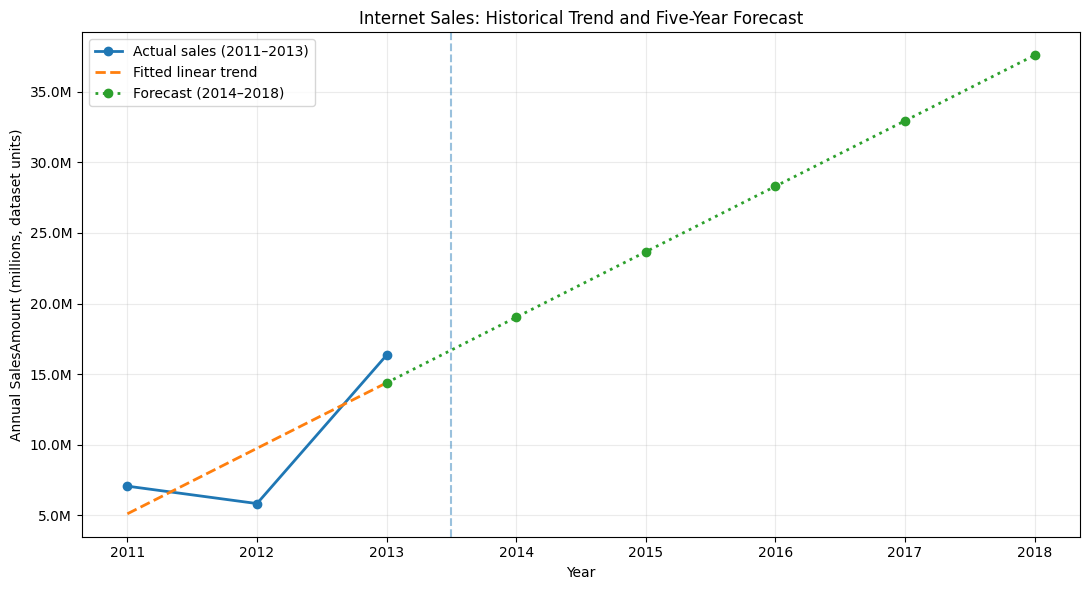

In [7]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(years, actual_sales, marker="o", linewidth=2, label="Actual sales (2011–2013)")
ax.plot(years, fitted_sales, linestyle="--", linewidth=2, label="Fitted linear trend")

# Connect predictions to the fitted 2013 value (not the actual 2013 value).
forecast_line_years = np.r_[years[-1], forecast_years]
forecast_line_sales = np.r_[fitted_sales[-1], forecast_values]
ax.plot(forecast_line_years, forecast_line_sales, marker="o", linestyle=":", linewidth=2,
        label="Forecast (2014–2018)")

ax.axvline(years[-1] + 0.5, linestyle="--", alpha=0.45)
ax.set_xticks(np.r_[years, forecast_years])
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value/1e6:.1f}M"))
ax.set_xlabel("Year")
ax.set_ylabel("Annual SalesAmount (millions, dataset units)")
ax.set_title("Internet Sales: Historical Trend and Five-Year Forecast")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## 8. Interpretation and limitations

**What this analysis can say**
- The 2011–2013 sales records provide a basis for a simple illustrative annual trend.
- The model extrapolates that trend to 2014–2018; it is **not** a forecast validated on unseen years.
- The highest-ranked product is the product with the greatest **observed historical total revenue**. The available calculations cannot establish which product *will* lead future sales.

**Main limitations**
1. **Only three annual points:** a five-year extrapolation is very sensitive to the fitted trend.
2. **Partial coverage:** 2010 and 2014 are excluded from annual model fitting because they do not represent the same observation window as full calendar years.
3. **No demand drivers:** the trend model excludes prices, promotions, seasonality, and product mix.
4. **No product-specific forecasting:** identifying the historically highest-revenue product is different from forecasting revenue for each product.

**Possible extension (not required for this assignment):** With more complete years, compare a linear model with a baseline forecast, and evaluate their out-of-sample prediction errors.